**Running in VS Code:** pick a Python kernel (top right) and run the setup cell below once if the packages are missing.

In [2]:
%pip install -q numpy matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


# Import dependencies

In [3]:

import numpy as np
import copy
import matplotlib.pyplot as plt
import sklearn
import sklearn.datasets
import sklearn.linear_model

 # Define dataset

In [4]:
def load_planar_dataset():
    np.random.seed(1)
    m = 400 # number of examples
    N = int(m/2) # number of points per class
    D = 2 # dimensionality
    X = np.zeros((m,D)) # data matrix where each row is a single example
    Y = np.zeros((m,1), dtype='uint8') # labels vector (0 for red, 1 for blue)
    a = 4 # maximum ray of the flower

    for j in range(2):
        ix = range(N*j,N*(j+1))
        t = np.linspace(j*3.12,(j+1)*3.12,N) + np.random.randn(N)*0.2 # theta
        r = a*np.sin(4*t) + np.random.randn(N)*0.2 # radius
        X[ix] = np.c_[r*np.sin(t), r*np.cos(t)]
        Y[ix] = j
        
    X = X.T
    Y = Y.T

    return X, Y

# Load dataset

In [5]:
X, Y = load_planar_dataset()

# Visualize the data

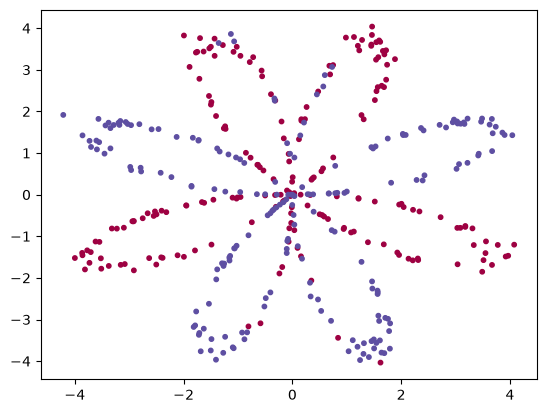

In [6]:
plt.scatter(X[0, :], X[1, :], c=Y, s=10, cmap=plt.cm.Spectral);

In [7]:
print ('The shape of X is: ', X.shape)
print ('The shape of Y is: ', Y.shape)
print ('I have m = %d training examples!', (X.shape[1]))

The shape of X is:  (2, 400)
The shape of Y is:  (1, 400)
I have m = %d training examples! 400


# Define the hidden layer size

In [8]:
hidden_layer_nodes = 4

def layer_sizes(X, Y):
    n_x = X.shape[0]
    n_h = hidden_layer_nodes
    n_y = Y.shape[0]

    return (n_x, n_h, n_y)

# Define activation function

In [9]:
def sigmoid(x):
    
    s = 1/(1+np.exp(-x))
    return s

# Define function for parameter (weight and bias) initialization

In [10]:
def initialize_parameters(n_x, n_h, n_y):
    
    np.random.seed(2)

    W1 = np.random.randn(n_h,n_x) * 0.01
    b1 = np.zeros((n_h,1))
    
    W2 = np.random.randn(n_y,n_h) * 0.01
    b2 = np.zeros((n_y,1))

    parameters = {"W1": W1,
                  "b1": b1,
                  "W2": W2,
                  "b2": b2}
    
    return parameters

# Forward propagation

In [11]:

def forward_propagation(X, parameters):
    
    W1 = parameters["W1"]
    b1 = parameters["b1"]
    W2 = parameters["W2"]
    b2 = parameters["b2"]
    
    Z1 = np.dot(W1,X) + b1
    A1 = np.tanh(Z1)
    
    Z2 = np.dot(W2,A1) + b2
    A2 = sigmoid(Z2)
    
    cache = {"Z1": Z1,
             "A1": A1,
             "Z2": Z2,
             "A2": A2}
    
    return A2, cache

# Compute cost

In [12]:
def compute_cost(A2, Y):

    m = Y.shape[1] # number of examples

    logprobs = np.multiply(Y, np.log(A2)) + np.multiply((1 - Y), np.log(1 - A2))
    cost = - np.multiply(1/m, np.sum(logprobs))  
    cost = float(np.squeeze(cost))                             
    
    return cost

# Backward propagation

In [13]:
def backward_propagation(parameters, cache, X, Y):

    m = X.shape[1]
    W1 = parameters["W1"]
    W2 = parameters["W2"]
    
    A1 = cache["A1"]
    A2 = cache["A2"]

    dZ2 = A2 - Y
    dW2 = np.multiply(1/m, np.dot(dZ2, np.transpose(A1)))
    db2 = np.multiply(1/m, np.sum(dZ2, axis = 1, keepdims = True))
    dZ1 = np.multiply(np.dot(np.transpose(W2), dZ2), (1 - np.power(A1, 2)))
    dW1 = np.multiply(1/m, np.dot(dZ1, np.transpose(X)))
    db1 = np.multiply(1/m, np.sum(dZ1, axis = 1, keepdims = True))
    
    grads = {"dW1": dW1,
             "db1": db1,
             "dW2": dW2,
             "db2": db2}
    
    return grads

# Update parameters

In [14]:

def update_parameters(parameters, grads, learning_rate = 1.2):
    
    W1 = copy.deepcopy(parameters["W1"]) 
    b1 = copy.deepcopy(parameters["b1"]) 
    W2 = copy.deepcopy(parameters["W2"]) 
    b2 = copy.deepcopy(parameters["b2"]) 
    
    dW1 = copy.deepcopy(grads["dW1"]) 
    db1 = copy.deepcopy(grads["db1"])
    dW2 = copy.deepcopy(grads["dW2"])
    db2 = copy.deepcopy(grads["db2"])
    
    W1 = W1 - learning_rate * dW1
    b1 = b1 - learning_rate * db1
    W2 = W2 - learning_rate * dW2
    b2 = b2 - learning_rate * db2

    parameters = {"W1": W1,
                  "b1": b1,
                  "W2": W2,
                  "b2": b2}
    
    return parameters

# Full NN model

In [15]:

def nn_model(X, Y, n_h, num_iterations = 10000, print_cost=False):
    
    np.random.seed(3)
    n_x = layer_sizes(X, Y)[0]
    n_y = layer_sizes(X, Y)[2]
    
    parameters = initialize_parameters(n_x, n_h, n_y)
   
    for i in range(0, num_iterations):
        
        A2, cache = forward_propagation(X, parameters)
        cost = compute_cost(A2, Y)
        grads = backward_propagation(parameters, cache, X, Y)
        parameters = update_parameters(parameters, grads, learning_rate = 1.2)
        
        # Print the cost every 1000 iterations
        if print_cost and i % 1000 == 0:
            print ("Cost after iteration %i: %f" %(i, cost))

    return parameters

# Test on our dataset

In [16]:
parameters = nn_model(X, Y, n_h = 4, num_iterations = 100000, print_cost=True)

Cost after iteration 0: 0.693048
Cost after iteration 1000: 0.288083
Cost after iteration 2000: 0.254385
Cost after iteration 3000: 0.233864
Cost after iteration 4000: 0.226792
Cost after iteration 5000: 0.222644
Cost after iteration 6000: 0.219731
Cost after iteration 7000: 0.217504
Cost after iteration 8000: 0.219447
Cost after iteration 9000: 0.218605
Cost after iteration 10000: 0.217904
Cost after iteration 11000: 0.217301
Cost after iteration 12000: 0.216780
Cost after iteration 13000: 0.216325
Cost after iteration 14000: 0.215921
Cost after iteration 15000: 0.215559
Cost after iteration 16000: 0.215231
Cost after iteration 17000: 0.214932
Cost after iteration 18000: 0.214658
Cost after iteration 19000: 0.214404
Cost after iteration 20000: 0.214169
Cost after iteration 21000: 0.213949
Cost after iteration 22000: 0.213744
Cost after iteration 23000: 0.213551
Cost after iteration 24000: 0.213369
Cost after iteration 25000: 0.213198
Cost after iteration 26000: 0.213035
Cost after ite

# Predict function

In [17]:
def predict(parameters, X):

    A2, cache = forward_propagation(X, parameters)
    predictions = (A2 > 0.5)

    return predictions

# Plot decision boundary

In [18]:
def plot_decision_boundary(model, X, y):
    # Set min and max values and give it some padding
    x_min, x_max = X[0, :].min() - 1, X[0, :].max() + 1
    y_min, y_max = X[1, :].min() - 1, X[1, :].max() + 1
    h = 0.01
    # Generate a grid of points with distance h between them
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    # Predict the function value for the whole grid
    Z = model(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    # Plot the contour and training examples
    plt.contourf(xx, yy, Z, cmap=plt.cm.Spectral)
    plt.ylabel('x2')
    plt.xlabel('x1')
    plt.scatter(X[0, :], X[1, :], c=y, cmap=plt.cm.Spectral)

Text(0.5, 1.0, 'Decision Boundary for hidden layer size 4')

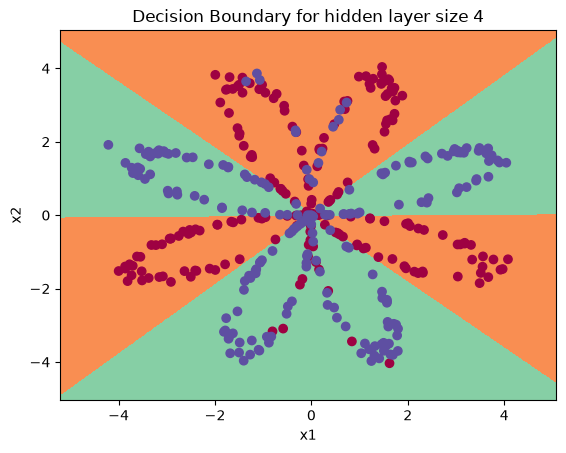

In [19]:
plot_decision_boundary(lambda x: predict(parameters, x.T), X, Y)
plt.title("Decision Boundary for hidden layer size " + str(4))

# Tuning hidden layer size

Accuracy for 1 hidden units: 67.5 %
Accuracy for 2 hidden units: 67.25 %
Accuracy for 3 hidden units: 90.75 %
Accuracy for 4 hidden units: 90.5 %
Accuracy for 5 hidden units: 91.25 %
Accuracy for 20 hidden units: 90.5 %
Accuracy for 50 hidden units: 90.75 %


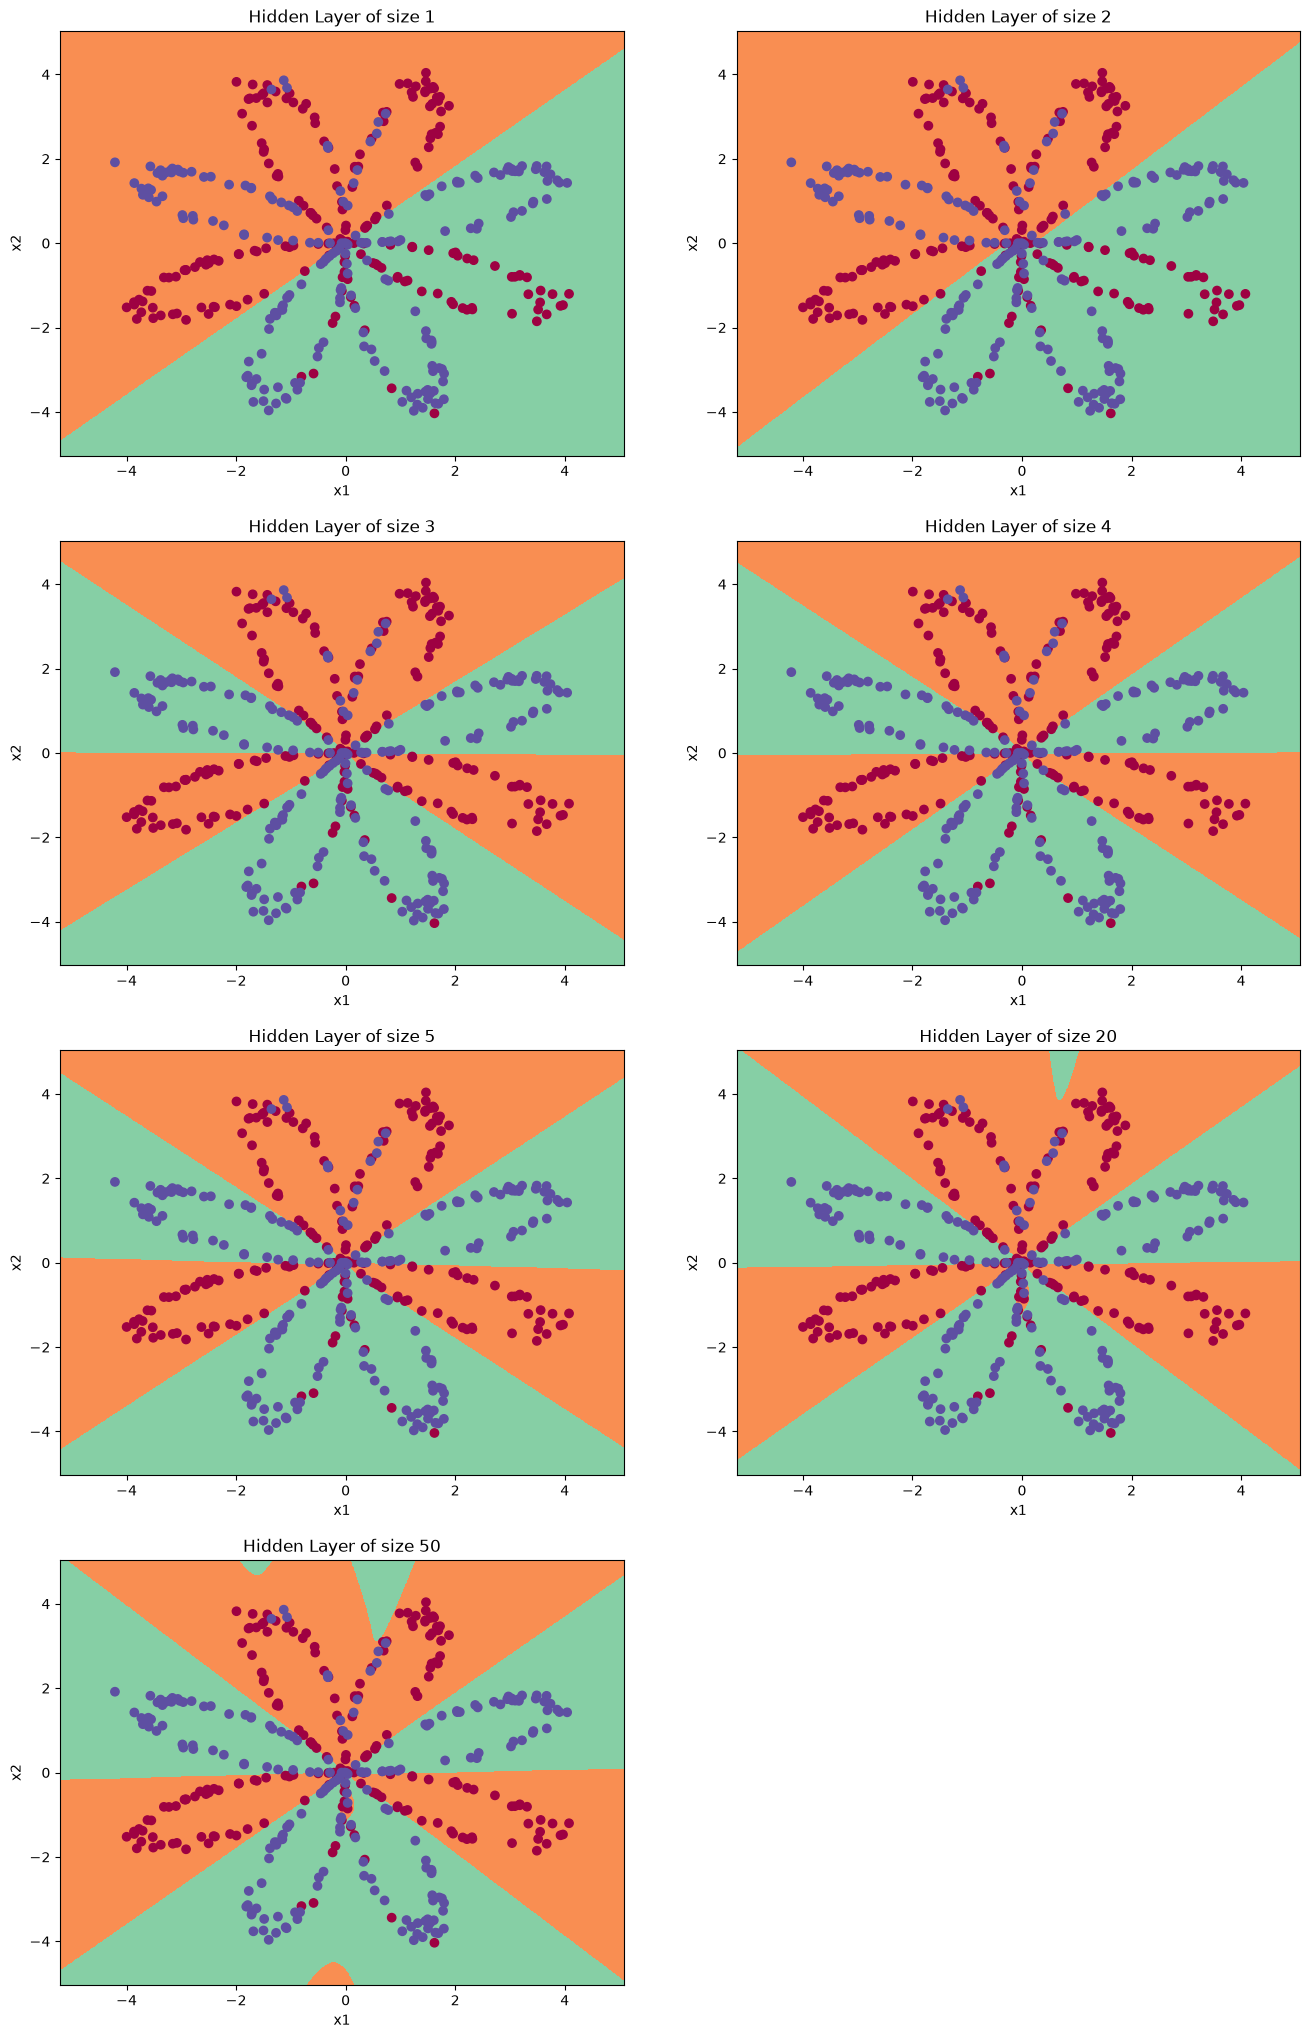

In [20]:
plt.figure(figsize=(16, 32))
hidden_layer_sizes = [1, 2, 3, 4, 5, 20, 50]
for i, n_h in enumerate(hidden_layer_sizes):
    plt.subplot(5, 2, i+1)
    plt.title('Hidden Layer of size %d' % n_h)
    parameters = nn_model(X, Y, n_h, num_iterations = 5000)
    plot_decision_boundary(lambda x: predict(parameters, x.T), X, Y)
    predictions = predict(parameters, X)
    accuracy = float(np.squeeze((np.dot(Y,predictions.T) + np.dot(1 - Y, 1 - predictions.T)) / float(Y.size)*100))  # squeeze keeps it working on newer NumPy
    print ("Accuracy for {} hidden units: {} %".format(n_h, accuracy))

## My experiments with other hidden layer sizes

First, a few more sizes with decision boundaries (kept up to 40 units so the plotting grid does not eat too much memory).

Accuracy for 6 hidden units: 90.50 %
Accuracy for 8 hidden units: 90.50 %
Accuracy for 10 hidden units: 90.25 %
Accuracy for 15 hidden units: 91.00 %
Accuracy for 30 hidden units: 91.00 %
Accuracy for 40 hidden units: 90.75 %


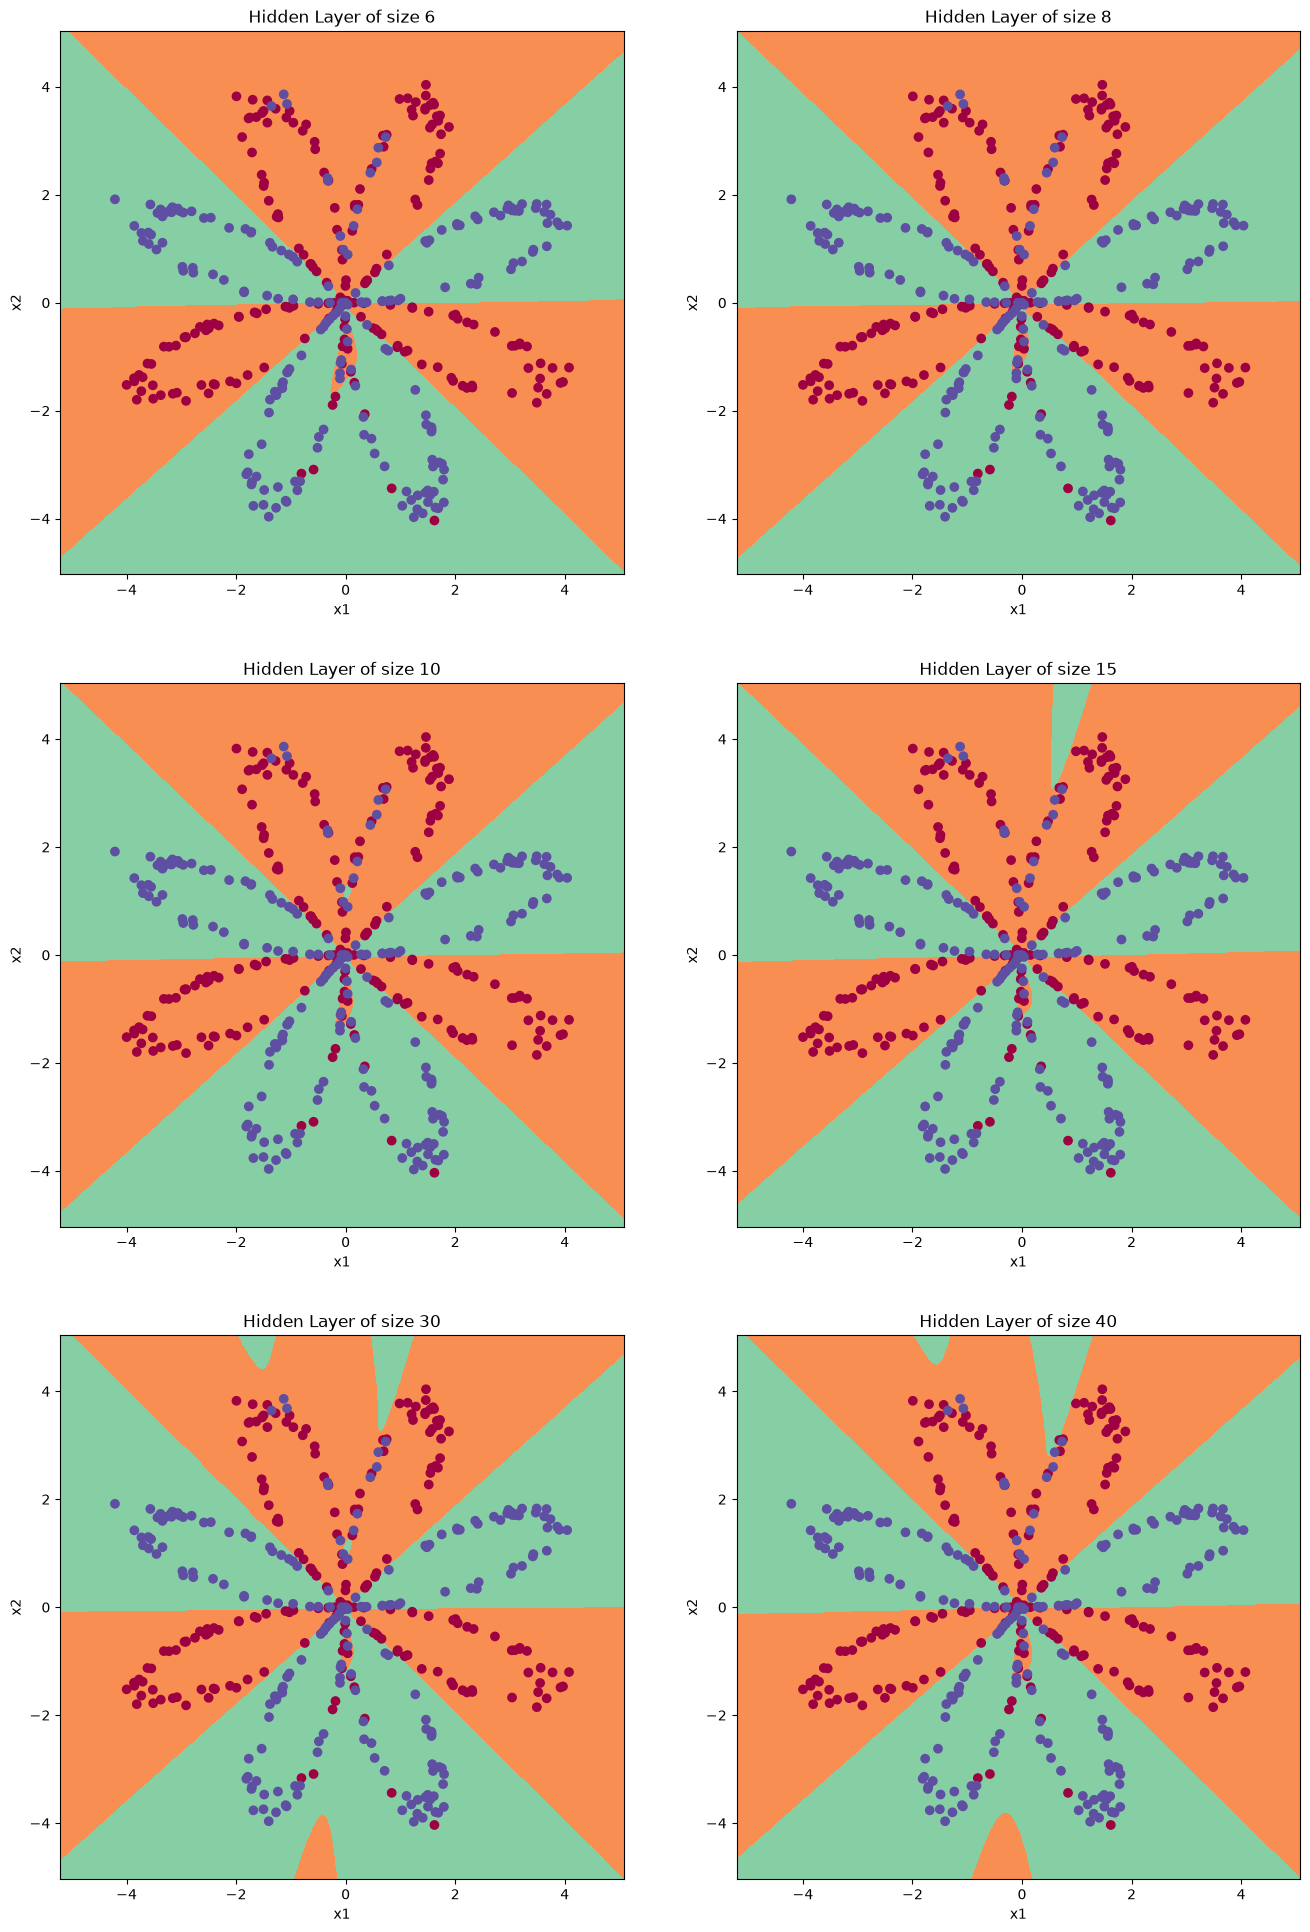

In [21]:
plt.figure(figsize=(16, 24))
more_sizes = [6, 8, 10, 15, 30, 40]
for i, n_h in enumerate(more_sizes):
    plt.subplot(3, 2, i+1)
    plt.title('Hidden Layer of size %d' % n_h)
    parameters = nn_model(X, Y, n_h, num_iterations = 5000)
    plot_decision_boundary(lambda x: predict(parameters, x.T), X, Y)
    predictions = predict(parameters, X)
    accuracy = ((Y == predictions).mean()) * 100
    print("Accuracy for {} hidden units: {:.2f} %".format(n_h, accuracy))

Now a compact comparison over many sizes (including very large ones), only looking at training accuracy, with the same 5000 iterations.

hidden units:   1  ->  training accuracy: 67.50 %
hidden units:   2  ->  training accuracy: 67.25 %
hidden units:   3  ->  training accuracy: 90.75 %
hidden units:   4  ->  training accuracy: 90.50 %
hidden units:   5  ->  training accuracy: 91.25 %
hidden units:   6  ->  training accuracy: 90.50 %
hidden units:   8  ->  training accuracy: 90.50 %
hidden units:  10  ->  training accuracy: 90.25 %
hidden units:  15  ->  training accuracy: 91.00 %
hidden units:  20  ->  training accuracy: 90.50 %
hidden units:  30  ->  training accuracy: 91.00 %
hidden units:  50  ->  training accuracy: 90.75 %
hidden units: 100  ->  training accuracy: 90.75 %
hidden units: 200  ->  training accuracy: 91.00 %


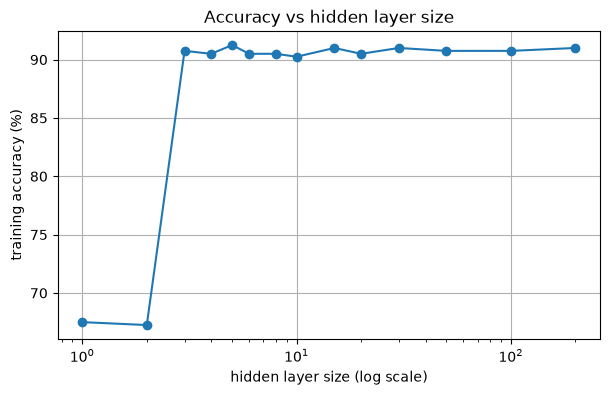

In [22]:
sizes = [1, 2, 3, 4, 5, 6, 8, 10, 15, 20, 30, 50, 100, 200]
accuracies = []
for n_h in sizes:
    params = nn_model(X, Y, n_h, num_iterations = 5000)
    acc = ((Y == predict(params, X)).mean()) * 100
    accuracies.append(acc)
    print("hidden units: {:>3}  ->  training accuracy: {:.2f} %".format(n_h, acc))

plt.figure(figsize=(7, 4))
plt.plot(sizes, accuracies, marker='o')
plt.xscale('log')
plt.xlabel('hidden layer size (log scale)')
plt.ylabel('training accuracy (%)')
plt.title('Accuracy vs hidden layer size')
plt.grid(True)
plt.show()

## Assignment: 

Run the notebook and test if everything runs fine. 

Test previous cell with different hidden layer size. 

Write your conclusion and observations.

## Conclusion and observations

I ran the whole notebook without errors. The network learns the "flower" dataset, and the cost goes from about 0.69 at the start down to about 0.21 after 100,000 iterations. Most of that drop happens in the first few thousand iterations, after that it only creeps down in the third decimal place.

**What I saw when changing the hidden layer size (5000 iterations, training accuracy):**

| hidden units | accuracy |
|---|---|
| 1 | 67.5 % |
| 2 | 67.25 % |
| 3 | 90.75 % |
| 4 | 90.5 % |
| 5 | 91.25 % |
| 6 / 8 / 10 | 90.25 % / 90.5 % / 90.25 % |
| 15 / 20 / 30 | 91.0 % / 90.5 % / 91.0 % |
| 50 / 100 / 200 | 90.25 % / 90.75 % / 90.5 % |

* **1 or 2 hidden units are too small.** The decision boundary is basically one straight line across the plot, so the model can only split the flower into two halves. That is why the accuracy stays around 67 %.
* **3 units is where it clicks.** The accuracy jumps to about 90 % and the boundary turns into several wedges that cut the flower into alternating red and blue sectors. The petals are not just a line anymore, so the model needs a few different "directions" to describe them.
* **After that it flattens out.** From 3 up to 200 units the accuracy stays between about 90 and 91 %, and the differences between sizes (for example 91.25 % for 5 units and 90.25 % for 50) are small enough that I would put them down to random initialization and not to the size itself. Making the layer 50 times bigger did not buy any extra accuracy.
* **Bigger layers start to draw odd shapes.** With 15 to 50 units small extra patches show up in the corners of the plot, in areas with no data at all, for example near the top and bottom edges. This is a sign the model is starting to fit noise and has more freedom than it needs (a bit of overfitting), even though the training accuracy does not show it. I only measured accuracy on the training data, so I cannot say for sure how it would do on new points.
* **Why it stays near 90 % and not 100 %.** All the boundaries are fan-shaped sectors that spread out from the middle, while the real petals curve and bend near their tips. A single hidden layer with tanh and this training setup does not follow those curved tips well, and the points near the center overlap a lot.

**Overall:** for this dataset a small hidden layer of about 3 to 5 units is enough. Going bigger only costs more computation and produces messier boundaries, and going smaller than 3 clearly hurts. The sweet spot is the smallest size that reaches the plateau.